# Projeto Integrador Final - Curso: Programação para Ciência de Dados

**Aluno:** Brener Gomes dos Santos  
**Data de Entrega:** 17 de Novembro de 2025, 18:00  
**Peso:** 30% da nota final

---

## <font color="red">INSTRUÇÕES - LEIA COM ATENÇÃO</font>

1. Coloque seu código nas células marcadas com `# === SEU CÓDIGO AQUI ===`
2. Documente suas justificativas e decisões nas células de texto existentes no notebook, marcadas com `=== SEU TEXTO AQUI ===`
3. **Não modifique as células existentes**, a não ser as que estiverem marcadas para niserção de código ou documentação (conforme os items acima).
4. Execute as funções de teste para verificar seu desenvolvimento. IMPORTANTE: as funções de teste não fazem parte do processo de correção. Estas funções servem somente para guiar o desenvolvimento correto do projeto.
5. Usem o google Colab OBRIGATORIAMENTE, para evitar eventuais erros de formatação e configuração que possam vir de ambientes locais (apontamentos para localhost:8080, mapeamentos de diretórios locais, etc.).
6. Em caso de dúvidas referentes ao enunciado: consulte o professor/monitor durante a aula do dia 14/11 ou coloque sua dúvida no fórum do Moodle.

### <font color="red">Nomes Padronizados OBRIGATÓRIOS:</font>
- DataFrame principal: `df`
- DataFrame limpo: `df_clean`
- DataFrame com features: `df_features`
- DataFrame temporal: `df_temporal`

### <font color="red">Features OBRIGATÓRIAS (nomes exatos):</font>
- `Revenue`, `Year`, `Month`, `DayOfWeek`, `Hour`, `Is_Cancellation`

### Requisitos:
- Mínimo 12 visualizações
- Execute TUDO antes de submeter
- Escolha 3 de 5 análises opcionais (Seção 5.2)


---
# Seção 1: Documentação e Contexto (5 pts)
---

## 1.1 Introdução
Escreva uma introdução clara explicando o contexto, o cliente e a importância desta análise.


# <font color="red">=== SEU TEXTO AQUI ===</font>


O CEO de uma varejista internacional de e-commerce especializada em produtos para presentes, operante há 2 anos no mercado, busca entender melhor o desempenho da empresa no período de 01/12/2012 até 08/12/2011.

Ele possui preocupações claras sobre como reter melhores clientes, onde investir em marketing, quais produtos merecem mais atenção e se são excessivamente dependentes de poucos países ou produtos.

Por isso busca melhores insights através de um serviço especializado em Ciência de Dados, visando traçar melhores estratégias para o o futuro da empresa.


## 1.2 Objetivos

Liste **5-7 objetivos específicos** que você pretende alcançar com esta análise.

**Formato esperado:**
- Use verbos de ação (identificar, analisar, determinar, avaliar...)
- Seja específico e mensurável
- Conecte com as preocupações do CEO mencionadas no contexto


### <font color="red">=== SEU TEXTO AQUI ===</font>
### Objetivos:
1. **Identificar** o nível de concentração de receita em poucos produtos e países, avaliando riscos de dependência.

2. **Analisar** o comportamento temporal da receita para detectar tendências, sazonalidade e oportunidades para ações de marketing.

3. **Avaliar** o valor e a contribuição dos principais clientes (Top 10–20%) para orientar estratégias de retenção.

4. **Determinar** quais produtos se destacam em volume e receita, apoiando decisões sobre foco comercial e marketing.

5. **Examinar** países e regiões com maior desempenho e potencial de crescimento.

6. **Mensurar** impacto dos cancelamentos e identificar padrões relacionados a produto, país ou período.

7. **Segmentar** comportamentos de compra para apoiar estratégias de upsell, cross-sell e aumento de ticket médio.


## 1.3 Perguntas de Negócio

Liste **5-7 perguntas específicas** que o CEO gostaria de ver respondidas.

**Formato esperado:**
- Perguntas diretas terminando em "?"
- Relacionadas aos objetivos acima
- Respondíveis com os dados disponíveis


### <font color="red">=== SEU TEXTO AQUI ===</font>
### Perguntas:
1. Quais produtos concentram a maior parte da receita e estamos dependentes de poucos itens?

2. Quais países mais contribuem para o faturamento e onde há maior potencial de expansão?

3. Como a receita evolui ao longo do tempo e quais períodos são ideais para intensificar campanhas de marketing?

4. Quem são os clientes mais valiosos e como podemos aumentar sua retenção?

5. Quais produtos têm maior potencial estratégico e merecem prioridade nas ações comerciais?

6. Qual é o impacto dos cancelamentos nas vendas e em quais segmentos eles ocorrem com mais frequência?

7. Existem padrões de comportamento de compra que podem orientar estratégias de aumento do ticket médio?



---
# Seção 2: Carregamento e Inspeção (5 pts)
---


In [2]:
# === IMPORTS ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('default')
%matplotlib inline

print("Bibliotecas importadas")


Bibliotecas importadas


In [3]:
# === CARREGAMENTO ===
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx'

df = pd.read_excel(url)
# Carregue o dataset em uma variável chamada 'df'

In [4]:
# === VALIDAÇÃO AUTOMÁTICA - NÃO MODIFICAR ===
def _validar_carregamento():
    """Valida se o dataset foi carregado corretamente."""
    try:
        # Verificar se df existe
        if 'df' not in globals():
            print("DataFrame 'df' não encontrado")
            return False

        _df = globals()['df']

        # Verificar tamanho mínimo
        if len(_df) <= 400000:
            print(f"Dataset muito pequeno: {len(_df):,} linhas (esperado: >400k)")
            return False

        # Verificar colunas essenciais
        _required = ['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'CustomerID', 'Country']
        _missing = [c for c in _required if c not in _df.columns]

        if _missing:
            print(f"Colunas ausentes: {_missing}")
            return False

        print("VALIDAÇÃO PASSOU - Dataset carregado corretamente!")
        print(f"   - {len(_df):,} transações")
        print(f"   - {_df.shape[1]} colunas")
        return True

    except Exception as e:
        print(f"Erro na validação: {e}")
        return False

# Executar validação
_validar_carregamento()

VALIDAÇÃO PASSOU - Dataset carregado corretamente!
   - 541,909 transações
   - 8 colunas


True

In [5]:
# === INSPEÇÃO INICIAL ===
# Execute os comandos abaixo e DOCUMENTE suas observações em markdown

# === SEU CÓDIGO AQUI ===

# 1. Primeiras linhas (entender estrutura)
# df.head(10)

# 2. Informações sobre tipos e memória
df.info()

# 3. Estatísticas descritivas (numéricas)
# df.describe()

# 4. Valores faltantes por coluna
# df.isnull().sum()

# 5. Valores únicos em colunas categóricas
# df['Country'].value_counts()
# df['StockCode'].nunique()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### <font color="red">=== SEU TEXTO AQUI ===</font>

### Observações iniciais:
- Existem no dataset, 541908 linhas e um total de 8 colunas;
- As colunas são 'InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country';
- Apenas 'Description' e 'Costumer' possuem valores vazios, sendo um número de 1454 e 135080 respectivamente;
- A empresa possui em média 15287.69 clientes e uma maior concentração de itens vendidos dentro do Reino Unido (UK) com 495478 de ocorrências nesse período, onde fica localizada sua sede, logo em seguida vem a Alemanha com 9495;
- A empresa fornece uma variedade de 4070 produtos em seu catálogo.

In [6]:
# === CONVERSÃO DE TIPOS (Pré-processamento Mínimo) ===
# OBRIGATÓRIO: Converter InvoiceDate para datetime
# NOTA: Embora esta seja a Seção de "Carregamento", é prática padrão
# converter tipos de data IMEDIATAMENTE após carregar, pois:
#   1. Permite análises temporais no EDA (Seção 3)
#   2. Evita erros downstream
#   3. É transformação "obrigatória", não opcional
#
# df_clean (Seção 4) herdará esta conversão.

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [7]:
# === VALIDAÇÃO AUTOMÁTICA - NÃO MODIFICAR ===
def _validar_tipos():
    """Valida se InvoiceDate foi convertido para datetime."""
    try:
        if 'df' not in globals():
            print("DataFrame 'df' não encontrado")
            return False

        _df = globals()['df']
        _date_col = 'InvoiceDate'

        if _date_col not in _df.columns:
            print(f"Coluna '{_date_col}' não encontrada")
            return False

        _is_datetime = pd.api.types.is_datetime64_any_dtype(_df[_date_col])

        if not _is_datetime:
            print(f"'{_date_col}' deve ser datetime, atual: {_df[_date_col].dtype}")
            print("   DICA: Use pd.to_datetime(df['InvoiceDate'])")
            return False

        print("VALIDAÇÃO PASSOU - InvoiceDate é datetime!")
        print(f"   - Tipo: {_df[_date_col].dtype}")
        print(f"   - Range: {_df[_date_col].min()} a {_df[_date_col].max()}")
        return True

    except Exception as e:
        print(f"Erro: {e}")
        return False

_validar_tipos()

VALIDAÇÃO PASSOU - InvoiceDate é datetime!
   - Tipo: datetime64[ns]
   - Range: 2010-12-01 08:26:00 a 2011-12-09 12:50:00


True

---
# Seção 3: Análise Exploratória - EDA (18 pts)
---

## 3.1 Análise Univariada (6 pts)
**Requisitos:** Mínimo 4 visualizações


============================== ANÁLISE EXPLORATÍRIA UNIVARIADA ==============================

HISTOGRAM: Quantity, UnitPrice, Revenue - considerando as 100 primeiras ocorrências


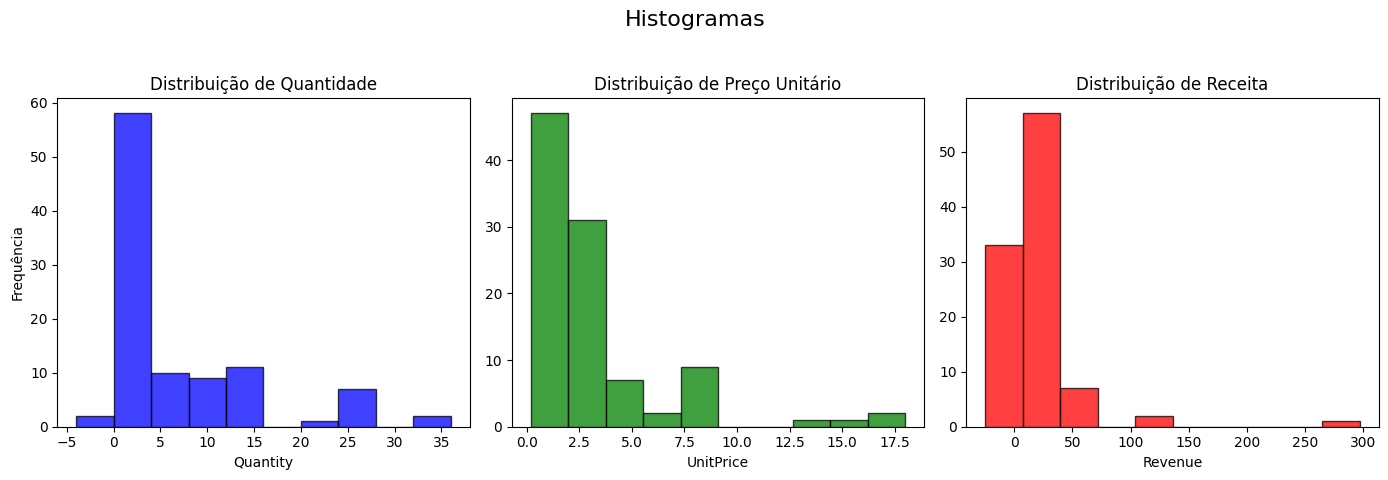

BOXPLOT: Quantity, UnitPrice, Revenue - para visualização de outliers


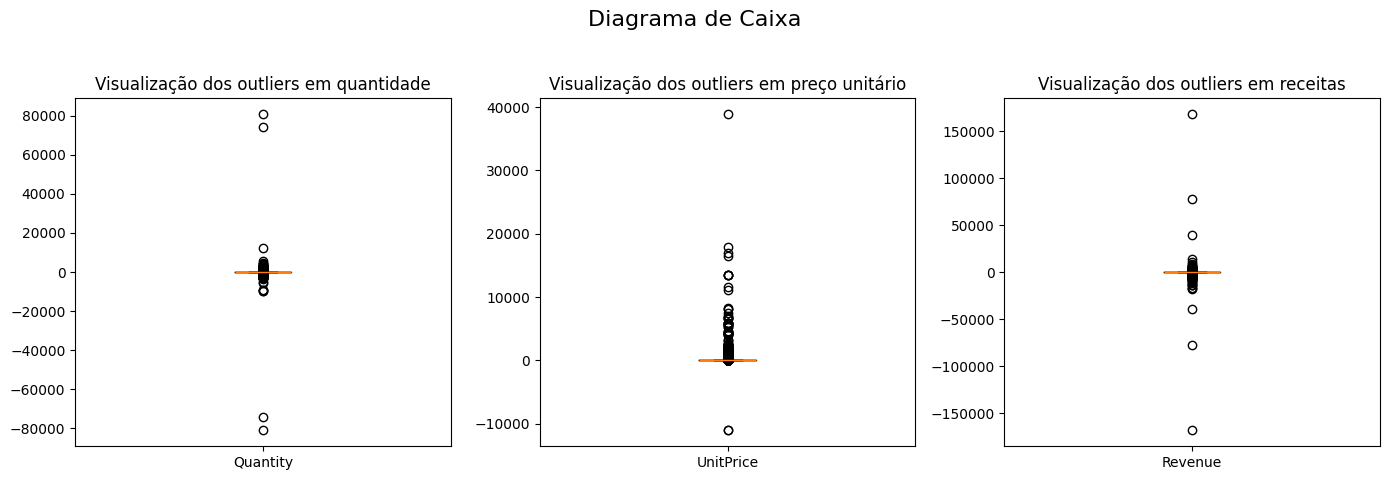

In [8]:
# === ANÁLISE UNIVARIADA ===
# Crie PELO MENOS 4 VISUALIZAÇÕES DIFERENTES para variáveis individuais

df['Revenue'] = df['Quantity'] * df['UnitPrice'] # Calcula a receita e atribui ao dataframe
df['Quantity'] = df['Quantity'].astype(float) # Converte 'Quantity' do tipo int para float

print('='*30 + ' ANÁLISE EXPLORATÍRIA UNIVARIADA ' + '='*30)
print('')

print('='*93)
print(f"HISTOGRAM: Quantity, UnitPrice, Revenue - considerando as 100 primeiras ocorrências")
print('='*93)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Histogramas', fontsize=16)

# Gráfico 1: Quantity
axes[0].hist(df['Quantity'].sample(100), bins=10, alpha=0.75, color='blue', edgecolor='black')
axes[0].set_title('Distribuição de Quantidade')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Frequência')

# Gráfico 2: UnitPrice
axes[1].hist(df['UnitPrice'].sample(100), bins=10, alpha=0.75, color='green', edgecolor='black')
axes[1].set_title('Distribuição de Preço Unitário')
axes[1].set_xlabel('UnitPrice')

# Gráfico 3: Revenue
axes[2].hist(df['Revenue'].sample(100), bins=10, alpha=0.75, color='red', edgecolor='black')
axes[2].set_title('Distribuição de Receita')
axes[2].set_xlabel('Revenue')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print('='*93)
print(f"BOXPLOT: Quantity, UnitPrice, Revenue - para visualização de outliers")
print('='*93)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Diagrama de Caixa', fontsize=16)


axes[0].boxplot(df['Quantity'], labels=['Quantity'])
axes[0].set_title('Visualização dos outliers em quantidade')
axes[1].boxplot(df['UnitPrice'], labels=['UnitPrice'])
axes[1].set_title('Visualização dos outliers em preço unitário')
axes[2].boxplot(df['Revenue'], labels=['Revenue'])
axes[2].set_title('Visualização dos outliers em receitas')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# SUGESTÕES (escolha pelo menos 4 tipos diferentes):
# • Histograma - distribuição de Quantity, UnitPrice, Revenue
# • Boxplot - identificar outliers em variáveis numéricas
# • Barplot - top 10 produtos, top 10 países
# • Countplot - frequência de cancelamentos
# • KDE plot - densidade de Revenue





### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
* Uma grande maioria das transações envolvem pequenas quantidades, preçoes unitãrios e também, receitas menores.
* Existe uma quantiade significativa de outliers de alto valor, indicando que, embora raras, existem vendas com volumes muito grandes, produtos muito caros e transações que geram uma receita acima do padrão.


## 3.2 Análise Bivariada (7 pts)
**Requisitos:** Mínimo 4 visualizações


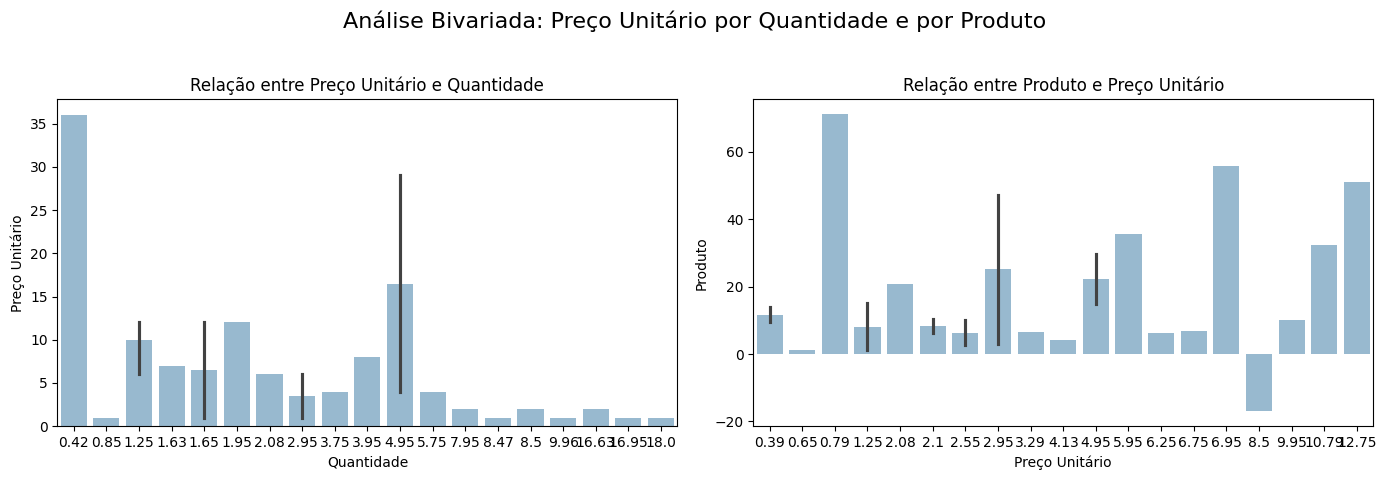

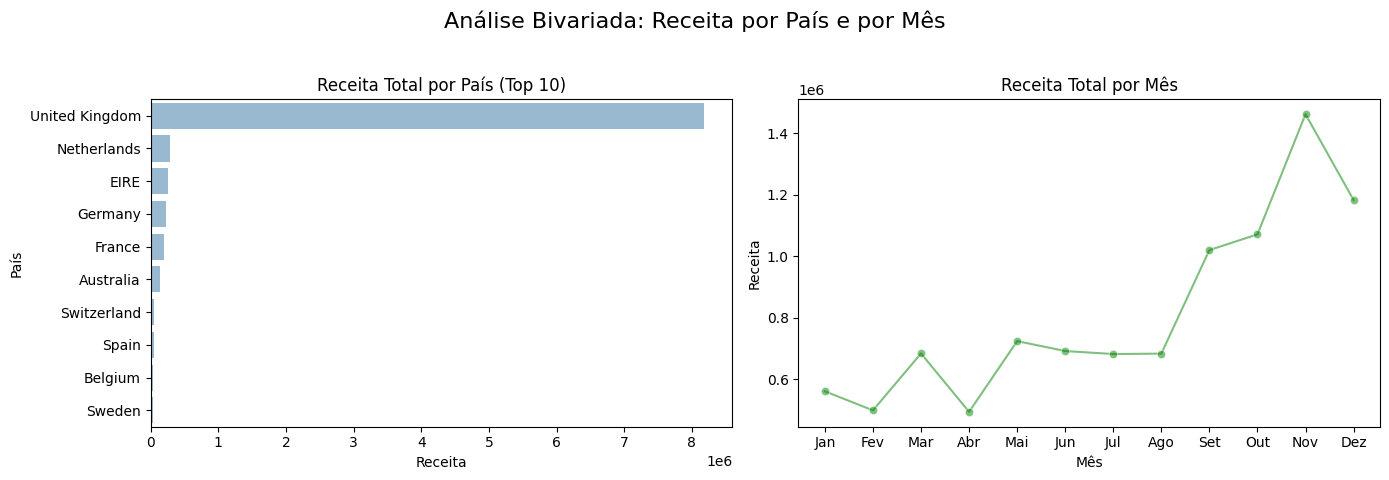

In [9]:
# === ANÁLISE BIVARIADA ===
# Explore RELAÇÕES entre 2 variáveis (mínimo 4 visualizações)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análise Bivariada: Preço Unitário por Quantidade e por Produto', fontsize=16)

# Gráfico 1: Quantity x UnitPrice
sns.barplot(x='UnitPrice', y='Quantity', data=df.sample(25), ax=axes[0], alpha=0.5)
axes[0].set_title('Relação entre Preço Unitário e Quantidade')
axes[0].set_xlabel('Quantidade')
axes[0].set_ylabel('Preço Unitário')

# Gráfico 1: Quantity x UnitPrice
sns.barplot(x='UnitPrice', y='Revenue', data=df.sample(25), ax=axes[1], alpha=0.5)
axes[1].set_title('Relação entre Produto e Preço Unitário')
axes[1].set_xlabel('Preço Unitário')
axes[1].set_ylabel('Produto')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análise Bivariada: Receita por País e por Mês', fontsize=16)

# Gráfico 3: Revenue x Country
revenue_by_country_all = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index()
sns.barplot(x='Revenue', y='Country', data=revenue_by_country_all, ax=axes[0], alpha=0.5)
axes[0].set_title('Receita Total por País (Top 10)')
axes[0].set_xlabel('Receita')
axes[0].set_ylabel('País')

# Gráfico 4: Revenue x Month
df['Month'] = df['InvoiceDate'].dt.month # Cria a coluna 'Month' a partir do 'InvoiceData'
revenue_by_month = df.groupby('Month')['Revenue'].sum().reset_index()
sns.lineplot(x='Month', y='Revenue', data=revenue_by_month, ax=axes[1], marker='o', color='green', alpha=0.5)
axes[1].set_title('Receita Total por Mês')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Receita')
axes[1].set_xticks(range(1, 13)) # Garante que todos os meses são exibidos
axes[1].set_xticklabels(['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# SUGESTÕES de relações importantes:
# • Quantity vs UnitPrice (correlação? comportamento de preço?)
# • Revenue por País (boxplot ou barplot)
# • Revenue por Mês (linha temporal)
# • Quantity por Dia da Semana (padrões semanais?)
# • UnitPrice por Produto (variação de preços)

### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
* Existe uma dependência extrema do Reuni Unido(UK). A receita nesse mercado é massivamente maior que os demais países, indicando um risco de concentração de mercado.
* A receita cresce ao longo do ano e atinge uma alta expreciva em novembro.


## 3.3 Análise Multidimensional (5 pts)

**Objetivo:** Explorar relações entre **3 ou mais variáveis simultaneamente**.

**Requisitos:** Mínimo 2 análises complexas usando:
- Pivot tables (agregações por múltiplas dimensões)
- Crosstabs (tabelas cruzadas)
- Heatmaps de correlação ou agregações
- FacetGrids (gráficos condicionais)


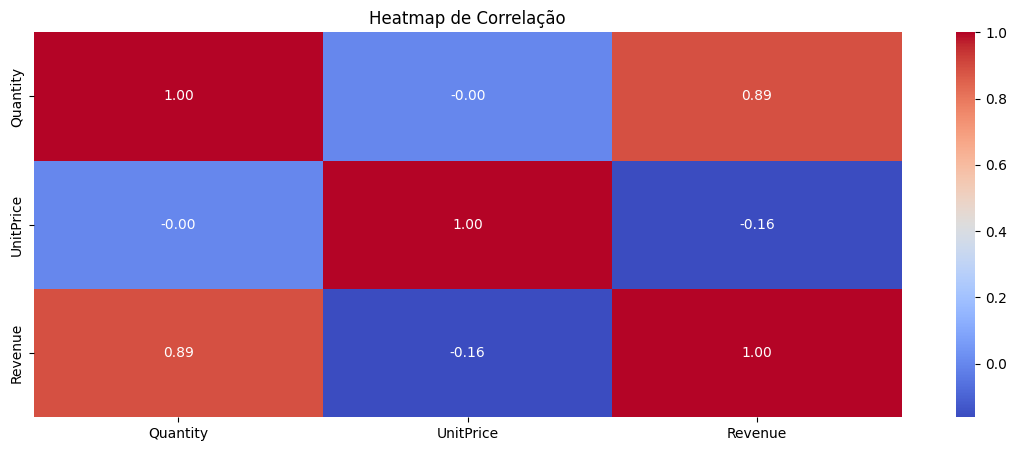

In [10]:
# === ANÁLISE MULTIDIMENSIONAL ===
matriz_corr = df[['Quantity', 'UnitPrice', 'Revenue']].corr()

plt.figure(figsize=(14, 5))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap de Correlação')
plt.show()


### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
[Suas observações]

---
# Seção 4: Pré-processamento (20 pts)
---

## 4.1 Limpeza (10 pts)


In [39]:
# === TRATAMENTO DE DADOS FALTANTES ===
# Analise os missing e DOCUMENTE sua estratégia

# === SEU CÓDIGO AQUI ===

# 1. Análise de missing
missing_count = df.isnull().sum()
missing_report = pd.DataFrame({
    'Column': missing_count.index,
    'Missing_Count': missing_count.values,
    'Missing_Pct': (missing_count.values / len(df)) * 100,
    'Dtype': df.dtypes.values
})

missing_report = missing_report[missing_report['Missing_Count'] > 0]
missing_report = missing_report.sort_values('Missing_Pct', ascending=False).reset_index(drop=True)

print(f"\nTotal de colunas com missing: {len(missing_report)}")
print(f"Coluna com mais missing: {missing_report.iloc[0]['Column']} ({missing_report.iloc[0]['Missing_Pct']:.2f}%)")
display(missing_report)

# 2. Decisão estratégica (JUSTIFIQUE E DOCUMENTE):

# A melhor estratégia é remover é remover as linhas faltantes de CustomerID,
# não seria viável atribuir resonsabilidade de representação de cliente
# através das linhas, pois cada ID representa um cliente distinto
# Podemos também identificar valores problemáticos em Quantity e UnitPrice
# essas duas variáveis não podem conter valores negativos

# 3. Aplicar estratégia escolhida
df_clean = df.dropna(subset=['CustomerID', 'Description']).copy()
df_clean = df_clean[df_clean['Quantity'] >= 0]
df_clean = df_clean[df_clean['UnitPrice'] >= 0]




Total de colunas com missing: 2
Coluna com mais missing: CustomerID (24.93%)


,Column,Missing_Count,Missing_Pct,Dtype
0,CustomerID,135080,24.926694,float64
1,Description,1454,0.268311,object


Linhas com UnitPrice == 0: 2515
Linhas com Quantity <= 0: 10624


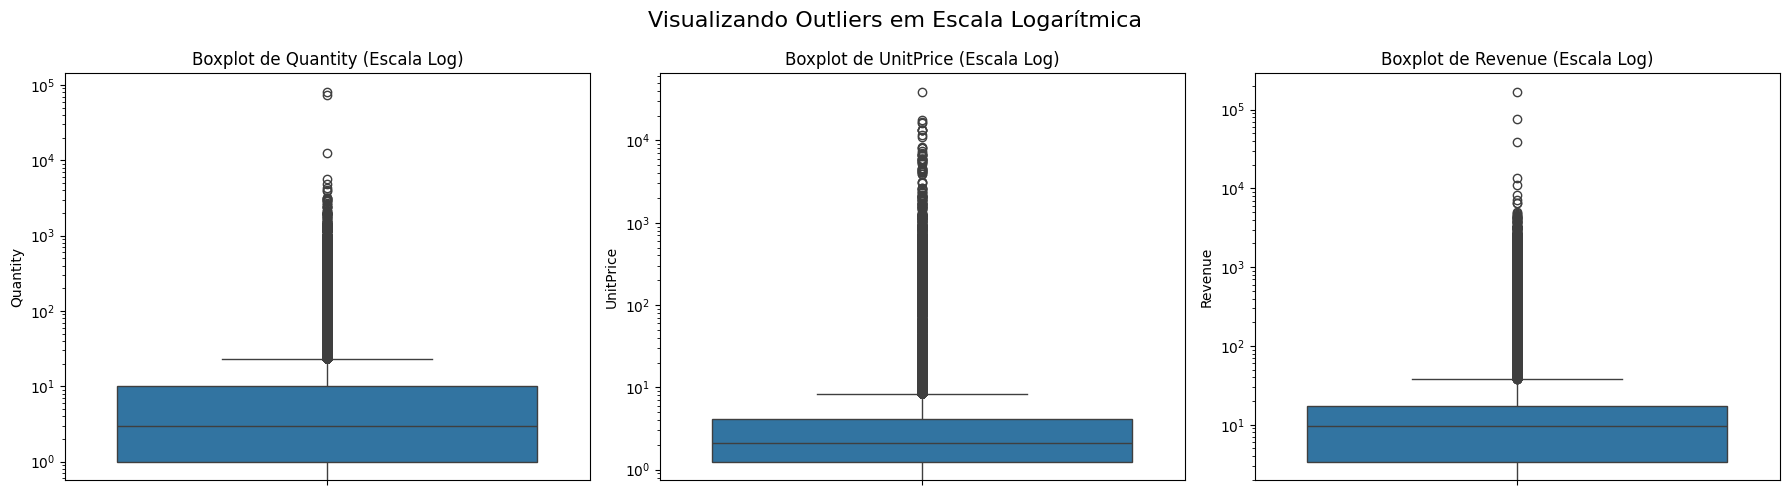

Linhas após o tratamento: 530100
Linhas removidas: 11809


In [47]:
# === TRATAMENTO DE OUTLIERS E INCONSISTÊNCIAS ===
# Identifique e trate valores problemáticos

# === SEU CÓDIGO AQUI ===

# 1. Identificar problemas comuns
print(f"Linhas com UnitPrice == 0: {len(df[df['UnitPrice'] == 0])}")
print(f"Linhas com Quantity <= 0: {len(df[df['Quantity'] <= 0])}")

# 2. Visualizar outliers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Visualizando Outliers em Escala Logarítmica', fontsize=16)

# Usendo a escala 'log' para visualizar melhor os outliers extremos e ver a caixa
sns.boxplot(data=df, y='Quantity', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Boxplot de Quantity (Escala Log)')

sns.boxplot(data=df, y='UnitPrice', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Boxplot de UnitPrice (Escala Log)')

sns.boxplot(data=df, y='Revenue', ax=axes[2])
axes[2].set_yscale('log')
axes[2].set_title('Boxplot de Revenue (Escala Log)')

plt.tight_layout()
plt.show()

# 3. Decisão estratégica (o que remover, manter, etc. - DOCUMENTE):
# Removemos as devoluções, preços zero ouo muito baixos e garante que a receita seja positiva


# 4. Aplicar tratamento
df_clean = df[df['Quantity'] > 0]
df_clean = df_clean[df_clean['UnitPrice'] > 0.001]
df_clean = df_clean[df_clean['Revenue'] > 0]

print(f"Linhas após o tratamento: {len(df_clean)}")
print(f"Linhas removidas: {len(df) - len(df_clean)}")




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
[Suas observações]

In [48]:
# === CRIAR DF_CLEAN ===
df_clean = df_clean.copy()  # Modifique conforme necessário

print(f"✓ df_clean: {df_clean.shape}")

✓ df_clean: (530100, 10)


In [49]:
# === VALIDAÇÃO AUTOMÁTICA - NÃO MODIFICAR ===
def _validar_limpeza():
    """Valida se df_clean foi criado adequadamente."""
    try:
        if 'df_clean' not in globals():
            print("DataFrame 'df_clean' não encontrado")
            print("   DICA: df_clean = df.copy() após sua limpeza")
            return False

        _df_clean = globals()['df_clean']
        _df = globals().get('df', None)

        if not isinstance(_df_clean, pd.DataFrame):
            print("df_clean deve ser DataFrame")
            return False

        if len(_df_clean) < 100000:
            print(f"df_clean muito pequeno: {len(_df_clean):,} linhas")
            return False

        _null_pct = _df_clean.isnull().sum().sum() / (len(_df_clean) * _df_clean.shape[1]) * 100

        print("VALIDAÇÃO PASSOU - df_clean criado!")
        if _df is not None:
            print(f"   - {len(_df_clean):,} linhas ({len(_df_clean)/len(_df)*100:.1f}% do original)")
        else:
            print(f"   - {len(_df_clean):,} linhas")
        print(f"   - Missing: {_null_pct:.2f}%")

        if _null_pct > 30:
            print("   AVISO: Alto percentual de missing (considere tratar)")

        return True

    except Exception as e:
        print(f"Erro: {e}")
        return False

_validar_limpeza()

VALIDAÇÃO PASSOU - df_clean criado!
   - 530,100 linhas (97.8% do original)
   - Missing: 2.49%


True

## 4.2 Feature Engineering (10 pts)


In [15]:
# === FEATURE: REVENUE ===
# OBRIGATÓRIO: Nome exato 'Revenue'

# === SEU CÓDIGO AQUI ===




In [16]:
# === FEATURES TEMPORAIS ===
# OBRIGATÓRIO: Year, Month, DayOfWeek, Hour

# === SEU CÓDIGO AQUI ===




In [17]:
# === FEATURE: IS_CANCELLATION ===
# OBRIGATÓRIO: Nome exato 'Is_Cancellation'

# === SEU CÓDIGO AQUI ===




In [18]:
# === FEATURES CRIATIVAS ===
# Crie pelo menos 3 features adicionais

# === SEU CÓDIGO AQUI ===




In [19]:
# === CRIAR DF_FEATURES ===
df_features = df_clean.copy()

print(f"✓ df_features: {df_features.shape}")


✓ df_features: (541909, 10)


### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
[Suas observações]

In [20]:
# === VALIDAÇÃO AUTOMÁTICA - NÃO MODIFICAR ===
def _validar_features():
    """Valida se features obrigatórias foram criadas."""
    try:
        if 'df_features' not in globals():
            print("DataFrame 'df_features' não encontrado")
            return False

        _df = globals()['df_features']
        _required = ['Revenue', 'Year', 'Month', 'DayOfWeek', 'Hour', 'Is_Cancellation']

        _missing = [f for f in _required if f not in _df.columns]
        _present = [f for f in _required if f in _df.columns]

        print(f"Features obrigatórias: {len(_present)}/{len(_required)}")

        for feat in _present:
            print(f"   {feat}")

        for feat in _missing:
            print(f"   {feat} - AUSENTE!")

        # Validações específicas
        if 'Revenue' in _df.columns:
            if _df['Revenue'].sum() <= 0:
                print("   Revenue deve ter valores positivos")

        if 'Is_Cancellation' in _df.columns:
            _unique = _df['Is_Cancellation'].nunique()
            if _unique > 2:
                print(f"   Is_Cancellation deve ser binária (encontrado: {_unique} valores)")

        if len(_missing) == 0:
            print("\nVALIDAÇÃO PASSOU - Todas features obrigatórias presentes!")
            return True
        else:
            print(f"\nATENÇÃO: {len(_missing)} feature(s) ausente(s)!")
            return False

    except Exception as e:
        print(f"Erro: {e}")
        return False

_validar_features()

Features obrigatórias: 2/6
   Revenue
   Month
   Year - AUSENTE!
   DayOfWeek - AUSENTE!
   Hour - AUSENTE!
   Is_Cancellation - AUSENTE!

ATENÇÃO: 4 feature(s) ausente(s)!


False

---
# Seção 5: Análise de Negócio (22 pts)
---

## 5.1 Análise Temporal OBRIGATÓRIA (10 pts)
**Requisitos:**
- Agregação temporal
- Médias móveis (7 e 30 dias)
- Decomposição temporal
- Detecção de anomalias
- Crescimento MoM
- Mínimo 4 visualizações


In [21]:
# === AGREGAÇÃO TEMPORAL ===
# Agrupe seus dados por DIA para análise de séries temporais

# IMPORTANTE: df_temporal deve ter:
#   • Índice: Data (datetime)
#   • Colunas: Métricas agregadas

# === SEU CÓDIGO AQUI ===



In [22]:
# === MÉDIAS MÓVEIS ===
# Calcule médias móveis de 7 e 30 dias para suavizar tendências

# IMPORTANTE: Crie colunas 'MA_7' e 'MA_30' em df_temporal

# === SEU CÓDIGO AQUI ===





In [23]:
# === DECOMPOSIÇÃO TEMPORAL ===
# Separe a série em: Tendência + Sazonalidade + Resíduo

from statsmodels.tsa.seasonal import seasonal_decompose

# === SEU CÓDIGO AQUI ===

# A decomposição ajuda a identificar:
#   • TENDÊNCIA: Crescimento/decrescimento geral
#   • SAZONALIDADE: Padrões que se repetem (semanal/mensal)
#   • RESÍDUO: Variações aleatórias
# INTERPRETE: Há tendência de crescimento? Há padrão semanal/mensal?




In [24]:
# === DETECÇÃO DE ANOMALIAS ===
# Identifique dias com receita ANORMALMENTE alta ou baixa
# Interprete os resultados (DOCUMENTE)

# === SEU CÓDIGO AQUI ===



In [25]:
# === CRESCIMENTO MOM (Month-over-Month) ===
# Calcule a variação percentual de receita entre meses consecutivos
# INTERPRETE: Quais meses tiveram maior crescimento? Há sazonalidade?

# === SEU CÓDIGO AQUI ===


### <font color="red">=== SEU TEXTO AQUI ===</font>
### Observações:
[Suas observações]

In [26]:
# === VALIDAÇÃO AUTOMÁTICA - NÃO MODIFICAR ===
def _validar_temporal():
    """Valida se análise temporal foi executada."""
    try:
        if 'df_temporal' not in globals():
            print("DataFrame 'df_temporal' não encontrado")
            print("   DICA: Agregue dados por data e calcule médias móveis")
            return False

        _df_temporal = globals()['df_temporal']

        print("df_temporal criado!")
        print(f"   - {len(_df_temporal)} períodos")

        # Verificar médias móveis
        _ma_cols = [c for c in _df_temporal.columns if 'MA' in c or 'moving' in c.lower()]

        if len(_ma_cols) >= 2:
            print(f"   Médias móveis encontradas: {', '.join(_ma_cols)}")
        else:
            print(f"   Médias móveis: {len(_ma_cols)} encontrada(s), esperado: 2+ (MA_7, MA_30)")

        # Verificar visualizações
        _num_figs = len(plt.get_fignums())
        print(f"   - Visualizações totais até agora: {_num_figs}")

        if _num_figs >= 10:
            print("   Bom progresso em visualizações!")
        else:
            print(f"   Crie mais visualizações (atual: {_num_figs}, mín: 12 no total)")

        return True

    except Exception as e:
        print(f"Erro: {e}")
        return False

_validar_temporal()

DataFrame 'df_temporal' não encontrado
   DICA: Agregue dados por data e calcule médias móveis


False

### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação Temporal:
[Quando intensificar marketing?]


## 5.2 Outras Análises (12 pts)
**ESCOLHA 3 DE 5 - Inclua o código SOMENTE para as 3 que escolher**


### 5.2.1 OPCIONAL 1: Produtos


In [27]:
# === ANÁLISE OPCIONAL 1: PRODUTOS ===

# # === SEU CÓDIGO AQUI ===




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação (Produtos):
[Se escolheu, escreva aqui]


### 5.2.2 OPCIONAL 2: Geografia


In [28]:
# === ANÁLISE OPCIONAL 2: GEOGRAFIA ===

# # === SEU CÓDIGO AQUI ===




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação (Geografia):
[Se escolheu, escreva aqui]


### 5.2.3 OPCIONAL 3: Clientes


In [29]:
# === ANÁLISE OPCIONAL 3: CLIENTES ===

# # === SEU CÓDIGO AQUI ===




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação (Clientes):
[Se escolheu, escreva aqui]


### 5.2.4 OPCIONAL 4: Comportamento


In [30]:
# === ANÁLISE OPCIONAL 4: COMPORTAMENTO ===
# Descomente se escolher esta análise

# # === SEU CÓDIGO AQUI ===




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação (Comportamento):
[Se escolheu, escreva aqui]


### 5.2.5 OPCIONAL 5: Cancelamentos


In [31]:
# === ANÁLISE OPCIONAL 5: CANCELAMENTOS ===
# Descomente se escolher esta análise

# # === SEU CÓDIGO AQUI ===




### <font color="red">=== SEU TEXTO AQUI ===</font>
### Recomendação (Cancelamentos):
[Se escolheu, escreva aqui]


---
# Seção 6: Insights e Recomendações (18 pts)
---

## 6.1 Top 5 Insights (6 pts)


### <font color="red">=== SEU TEXTO AQUI ===</font>
### TOP 5 INSIGHTS:

#### 1. [Insight 1]
**Descoberta:** ...
**Impacto:** ...
**Urgência:** Alta/Média/Baixa

#### 2. [Insight 2]
...

#### 3. [Insight 3]
...

#### 4. [Insight 4]
...

#### 5. [Insight 5]
...


## 6.2 Resumo Executivo (6 pts)
**Máximo 300 palavras, linguagem não-técnica**


### <font color="red">=== SEU TEXTO AQUI ===</font>
### RESUMO EXECUTIVO:

[Escreva aqui - máx 300 palavras]


## 6.3 Top 3 Recomendações (6 pts)


### <font color="red">=== SEU TEXTO AQUI ===</font>
### RECOMENDAÇÕES:

#### Recomendação 1:
**Ação:** ...
**KPI:** ...
**Riscos:** ...
**Timeline:** ...

#### Recomendação 2:
...

#### Recomendação 3:
...


In [32]:
# === VALIDAÇÃO FINAL - NÃO MODIFICAR ===
def _validacao_final():
    """Fornece resumo completo do projeto."""
    print("="*60)
    print("VALIDAÇÃO FINAL - PROJETO INTEGRADOR")
    print("="*60)

    _resultados = {}

    # 1. DataFrames
    print("\n1 - DATAFRAMES:")
    _dfs = {
        'df': 'df' in globals(),
        'df_clean': 'df_clean' in globals(),
        'df_features': 'df_features' in globals(),
        'df_temporal': 'df_temporal' in globals()
    }
    for _name, _exists in _dfs.items():
        print(f"   {'OK: ' if _exists else 'ERRO: '} {_name}")
        _resultados[_name] = _exists

    # 2. Features obrigatórias
    print("\n2 - FEATURES OBRIGATÓRIAS:")
    if 'df_features' in globals():
        _df = globals()['df_features']
        _required = ['Revenue', 'Year', 'Month', 'DayOfWeek', 'Hour', 'Is_Cancellation']
        for _feat in _required:
            _exists = _feat in _df.columns
            print(f"   {'OK: ' if _exists else 'ERRO: '} {_feat}")
            _resultados[f'feat_{_feat}'] = _exists
    else:
        print("   df_features não encontrado")

    # 3. Visualizações
    print("\n3 - VISUALIZAÇÕES:")
    _num_viz = len(plt.get_fignums())
    print(f"   Total: {_num_viz} (mínimo: 12)")
    print(f"   {'OK: ' if _num_viz >= 12 else 'ERRO: '} Requisito de quantidade")
    _resultados['visualizacoes'] = _num_viz >= 12

    # 4. Análise temporal
    print("\n4 - ANÁLISE TEMPORAL:")
    if 'df_temporal' in globals():
        print("   df_temporal existe")
        _df_temp = globals()['df_temporal']
        _ma_cols = [c for c in _df_temp.columns if 'MA' in c or 'moving' in c.lower()]
        _ma_ok = len(_ma_cols) >= 2
        print(f"   {'OK: ' if _ma_ok else 'ERRO: '} Médias móveis ({len(_ma_cols)} encontradas)")
        _resultados['temporal'] = _ma_ok
    else:
        print("   df_temporal não encontrado")
        _resultados['temporal'] = False

    # 5. Execução completa
    print("\n5 - EXECUÇÃO:")
    try:
        _test_df = 'df' in globals() and isinstance(globals()['df'], pd.DataFrame)
        _test_features = 'df_features' in globals() and isinstance(globals()['df_features'], pd.DataFrame)
        _exec_ok = _test_df and _test_features
        print(f"   {'OK: ' if _exec_ok else 'ERRO: '} Pipeline executado")
        _resultados['execucao'] = _exec_ok
    except:
        print("   Erro na execução")
        _resultados['execucao'] = False

    print("\n" + "="*60)
    print("Esta validação é apenas um GUIA!")
    print("A nota final depende de qualidade, insights e recomendações.")
    print("="*60)

    return _resultados

_validacao_final()

VALIDAÇÃO FINAL - PROJETO INTEGRADOR

1 - DATAFRAMES:
   OK:  df
   OK:  df_clean
   OK:  df_features
   ERRO:  df_temporal

2 - FEATURES OBRIGATÓRIAS:
   OK:  Revenue
   ERRO:  Year
   OK:  Month
   ERRO:  DayOfWeek
   ERRO:  Hour
   ERRO:  Is_Cancellation

3 - VISUALIZAÇÕES:
   Total: 0 (mínimo: 12)
   ERRO:  Requisito de quantidade

4 - ANÁLISE TEMPORAL:
   df_temporal não encontrado

5 - EXECUÇÃO:
   OK:  Pipeline executado

Esta validação é apenas um GUIA!
A nota final depende de qualidade, insights e recomendações.


{'df': True,
 'df_clean': True,
 'df_features': True,
 'df_temporal': False,
 'feat_Revenue': True,
 'feat_Year': False,
 'feat_Month': True,
 'feat_DayOfWeek': False,
 'feat_Hour': False,
 'feat_Is_Cancellation': False,
 'visualizacoes': False,
 'temporal': False,
 'execucao': True}

---
# CHECKLIST FINAL

Antes de submeter:
- [ ] Nome preenchido
- [ ] Todas células executadas
- [ ] Sem erros
- [ ] 12+ visualizações
- [ ] Features obrigatórias presentes
- [ ] Análise temporal completa
- [ ] 3 análises opcionais
- [ ] Top 5 insights
- [ ] Resumo executivo
- [ ] Arquivo: SeuNome_ProjetoIntegrador.ipynb

**Boa sorte!**
